In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\Pranjali\CODSOFT_TASK4
['.ipynb_checkpoints', 'sms_spam_detection.ipynb', 'spam.csv']


In [7]:

import pandas as pd

df = pd.read_csv("spam.csv", encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 5)


,ï»¿v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [8]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Column names:
['ï»¿v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Missing values:
ï»¿v1            0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

First 5 rows:


,ï»¿v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [9]:


df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("Columns after cleaning:")
print(df.columns.tolist())

display(df.head())

Columns after cleaning:
['ï»¿v1', 'v2']


,ï»¿v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:

df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})

print(df.columns.tolist())
display(df.head())

['ï»¿v1', 'message']


,ï»¿v1,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [12]:

print("Current column names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Current column names:
['ï»¿v1', 'message']

First 5 rows:


,ï»¿v1,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [13]:

df.columns = df.columns.astype(str).str.strip()

df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})

print("Updated columns:", df.columns.tolist())

Updated columns: ['ï»¿v1', 'message']


In [15]:

# Remove extra characters and spaces from column names
df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()

# Rename columns
df = df.rename(columns={
    "v1": "label",
    "message": "message"
})

print("Updated column names:", df.columns.tolist())
display(df.head())

Updated column names: ['label', 'message']


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [16]:

print("Message category counts:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df[["label", "message"]].isnull().sum())

Message category counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [17]:

df = df.dropna(subset=["label", "message"])
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("Duplicate messages remaining:", df.duplicated().sum())

Dataset shape after cleaning: (5169, 2)
Duplicate messages remaining: 0


In [19]:

df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("Label mapping: ham = 0, spam = 1")
print(df[["label", "label_num", "message"]].head())

print("\nEncoded label counts:")
print(df["label_num"].value_counts())

Label mapping: ham = 0, spam = 1
  label  label_num                                            message
0   ham          0  Go until jurong point, crazy.. Available only ...
1   ham          0                      Ok lar... Joking wif u oni...
2  spam          1  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham          0  U dun say so early hor... U c already then say...
4   ham          0  Nah I don't think he goes to usf, he lives aro...

Encoded label counts:
label_num
0    4516
1     653
Name: count, dtype: int64


In [20]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [21]:

X = df["message"].astype(str)
y = df["label_num"]

print("Total messages:", len(X))
print("Total labels:", len(y))
print("\nLabel distribution:")
print(y.value_counts())

Total messages: 5169
Total labels: 5169

Label distribution:
label_num
0    4516
1     653
Name: count, dtype: int64


In [22]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [23]:

spam_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

spam_model.fit(X_train, y_train)

print("SMS Spam Detection model trained successfully!")

SMS Spam Detection model trained successfully!


In [24]:

y_pred = spam_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham (Legitimate)", "Spam"]
))

Model Accuracy: 95.16%

Classification Report:
                  precision    recall  f1-score   support

Ham (Legitimate)       0.95      1.00      0.97       903
            Spam       1.00      0.62      0.76       131

        accuracy                           0.95      1034
       macro avg       0.97      0.81      0.87      1034
    weighted avg       0.95      0.95      0.95      1034



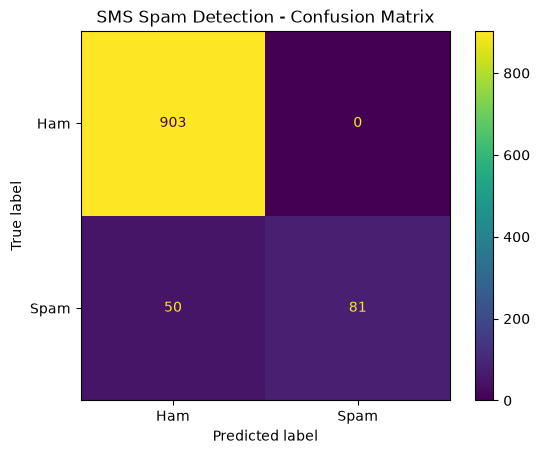

In [25]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

In [26]:

from sklearn.metrics import precision_score, recall_score, f1_score

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

Accuracy:  0.9516
Precision: 1.0000
Recall:    0.6183
F1-Score:  0.7642


In [27]:

message = ["Hey, are we still meeting for lunch today?"]

prediction = spam_model.predict(message)[0]

if prediction == 1:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM (Legitimate)")

print("Message:", message[0])

Prediction: HAM (Legitimate)
Message: Hey, are we still meeting for lunch today?


In [28]:

message = ["Congratulations! You have won a free prize. Call now to claim your reward!"]

prediction = spam_model.predict(message)[0]

if prediction == 1:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM (Legitimate)")

print("Message:", message[0])

Prediction: SPAM
Message: Congratulations! You have won a free prize. Call now to claim your reward!


In [29]:

def predict_sms(message):
    prediction = spam_model.predict([message])[0]

    if prediction == 1:
        result = "SPAM"
    else:
        result = "HAM (Legitimate)"

    print("Message:", message)
    print("Prediction:", result)

predict_sms("You have won a free mobile phone. Click here!")

Message: You have won a free mobile phone. Click here!
Prediction: HAM (Legitimate)


In [30]:

import joblib

joblib.dump(spam_model, "sms_spam_detection_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [31]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

display(results)

results.to_csv("model_evaluation_results.csv", index=False)

print("Evaluation results saved successfully!")

,Metric,Score
0,Accuracy,0.951644
1,Precision,1.000000
2,Recall,0.618321
3,F1-Score,0.764151


Evaluation results saved successfully!


In [32]:

import os

print("Current project folder:")
print(os.getcwd())

print("\nFiles in project folder:")
for file in os.listdir():
    print(file)

Current project folder:
C:\Users\Pranjali\CODSOFT_TASK4

Files in project folder:
.ipynb_checkpoints
model_evaluation_results.csv
sms_spam_detection.ipynb
sms_spam_detection_model.pkl
spam.csv


In [33]:

loaded_model = joblib.load("sms_spam_detection_model.pkl")

test_message = [
    "Congratulations! You have won a free prize. Call now!"
]

prediction = loaded_model.predict(test_message)[0]

print("Test message:", test_message[0])
print("Prediction:", "SPAM" if prediction == 1 else "HAM (Legitimate)")

Test message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM


In [34]:

test_messages = [
    "Hi, how are you doing today?",
    "Congratulations! You won a free cash prize. Claim now!",
    "Please call me when you reach home.",
    "URGENT! You have won a free vacation. Call now!"
]

predictions = loaded_model.predict(test_messages)

for message, prediction in zip(test_messages, predictions):
    label = "SPAM" if prediction == 1 else "HAM (Legitimate)"
    print(f"{label}: {message}\n")

HAM (Legitimate): Hi, how are you doing today?

SPAM: Congratulations! You won a free cash prize. Claim now!

HAM (Legitimate): Please call me when you reach home.

SPAM: URGENT! You have won a free vacation. Call now!



In [35]:

requirements = """pandas
scikit-learn
matplotlib
joblib
openpyxl
"""

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [36]:

readme = """# SMS Spam Detection

## Project Overview
This project uses Machine Learning and Natural Language Processing (NLP)
to classify SMS messages as Spam or Ham (legitimate messages).

## Objective
To identify unwanted or fraudulent SMS messages automatically.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorization
- Multinomial Naive Bayes
- Matplotlib
- Jupyter Notebook

## Dataset
The dataset contains SMS messages labelled as:
- Ham: Legitimate messages
- Spam: Unwanted messages

## Machine Learning Workflow
1. Load the dataset.
2. Clean the data and remove duplicates.
3. Convert labels into numerical values.
4. Split data into training and testing sets.
5. Convert text into numerical features using TF-IDF.
6. Train a Multinomial Naive Bayes classifier.
7. Evaluate the model using accuracy, precision, recall, F1-score,
   and a confusion matrix.
8. Test the model on new SMS messages.

## Model
TF-IDF + Multinomial Naive Bayes

## Project Files
- sms_spam_detection.ipynb: Project notebook
- sms_spam_detection_model.pkl: Trained model
- model_evaluation_results.csv: Evaluation results
- requirements.txt: Required Python libraries

## How to Run
1. Install Python.
2. Install dependencies using:
   pip install -r requirements.txt
3. Open the notebook in Jupyter Notebook.
4. Run the cells in order.

## Future Improvements
- Compare Naive Bayes with Logistic Regression and SVM.
- Build a simple web interface.
- Test the model on a larger and more varied SMS dataset.

## Author
Pranjali Jamadade

## Internship
CodSoft Machine Learning Internship
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [37]:

import os

required_files = [
    "sms_spam_detection.ipynb",
    "spam.csv",
    "sms_spam_detection_model.pkl",
    "model_evaluation_results.csv",
    "requirements.txt",
    "README.md"
]

for filename in required_files:
    if os.path.exists(filename):
        print("FOUND:", filename)
    else:
        print("NOT FOUND:", filename)

FOUND: sms_spam_detection.ipynb
FOUND: spam.csv
FOUND: sms_spam_detection_model.pkl
FOUND: model_evaluation_results.csv
FOUND: requirements.txt
FOUND: README.md


In [40]:

import os
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

project_folder = r"C:\Users\Pranjali\CODSOFT_TASK4"
os.makedirs(project_folder, exist_ok=True)

joblib.dump(spam_model, os.path.join(project_folder, "sms_spam_detection_model.pkl"))

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})
results.to_csv(os.path.join(project_folder, "model_evaluation_results.csv"), index=False)

with open(os.path.join(project_folder, "requirements.txt"), "w", encoding="utf-8") as f:
    f.write("pandas\nscikit-learn\nmatplotlib\njoblib\nopenpyxl\n")

readme = """# SMS Spam Detection

## Project Overview
A Machine Learning project that classifies SMS messages as Spam or Ham.

## Technologies
- Python
- Pandas
- Scikit-learn
- TF-IDF
- Multinomial Naive Bayes
- Matplotlib

## Workflow
1. Load and clean SMS data.
2. Encode labels.
3. Split data into training and testing sets.
4. Convert text using TF-IDF.
5. Train a Naive Bayes classifier.
6. Evaluate the model and test new messages.

## Files
- sms_spam_detection.ipynb
- spam.csv
- sms_spam_detection_model.pkl
- model_evaluation_results.csv
- requirements.txt

## Author
Pranjali Jamadade

## Internship
CodSoft Machine Learning Internship
"""

with open(os.path.join(project_folder, "README.md"), "w", encoding="utf-8") as f:
    f.write(readme)

print("Project folder:", project_folder)
print(os.listdir(project_folder))

Project folder: C:\Users\Pranjali\CODSOFT_TASK4
['.ipynb_checkpoints', 'model_evaluation_results.csv', 'README.md', 'requirements.txt', 'sms_spam_detection.ipynb', 'sms_spam_detection_model.pkl', 'spam.csv']
